Markdown
#Group Information 
Members: Shishir, Royar, Hasir
Members Name: Shishir Dahal
Student ID: 313101

Markdown
#Task I.1 - Problem Description and Dataset (Paderborn University Bearing Data)

1. Description of Engineering System, Measurements and Data Origin

(i) Engineering System:
 The system is an accelerated lifetime test rig (Test Setup KA) at the Chair of Design and Drive Technology, Paderborn University. The test rig comprises of a test motor module, a measuring shaft module, a radial force module, a flywheel module, and a load motor module.
(ii) Measurements and Sensors:
High frequency multi sensor data acquisition system captures physical parameters during bearing operation. The parameters include motor current, vibration, mechanical parameters (load force, torque, and speed) and temperature.
(iii) Data Origin:
The dataset includes healthy baseline deep groove ball bearings (K001), and bearings with artificial damages (KA01 and KI01) introduced by EDM(Electrical Discharge Machining). The dataset also includes bearing test conditions (predefined heating load and variability of test loads (KO, K1, K2 and K3)).

2. Description of Input Features and Classification Targets

(i) Input Features: The complete Paderborn dataset contains vibration signals, motor-current measurements, and operating-condition variables (speed, temperature, load, and torque). In this project, only the vibration_1 signal was used, from which RMS, peak amplitude, crest factor, and kurtosis features were extracted for classification.
(ii) Classification Targets: 
Classification Target: Multi-class classification or binary classification problem to specify the state of bearing health and fault location, particularly differentiating between healthy operation (`K001`), outer ring defect (`KA01`: single-point EDM (Electrical Discharge Machining) defect of 0.25 mm length and 1 mm width/depth) and inner ring defect (`KI01`: single-point EDM defect).

3. Engineering Relevance of the Classification Problem
Industrial Impact: Automated condition monitoring of rolling bearings provides predictive maintenance of industrial drives and avoids unexpected equipment breakdowns, unplanned production stoppages and costly repair work.

4. Dataset Citation, URL, and License
 Dataset Name: Paderborn University Bearing Data Center Dataset (Bearings: `K001`, `KA01`, `KI01`).
 Origin/Authors: Chair of Design and Drive Technology, Paderborn University (Prof. Dr.-Ing. Detmar Zimmer, Dipl.-Ing. Christian Lessmeier, Waldemar Dück, Stefan Brocke).
 URL: Data Sets and Download - Konstruktions- und Antriebstechnik (KAt) | Universität Paderborn
 License/Usage: Publicly available research benchmark dataset provided for scientific analysis, fault detection algorithm development, and machine learning research.


Shape (rows, columns): (384, 6)

Data types:
 piece             int64
label             int64
rms             float64
peak            float64
crest_factor    float64
kurtosis        float64
dtype: object

Missing values:
 piece           0
label           0
rms             0
peak            0
crest_factor    0
kurtosis        0
dtype: int64

Duplicate rows: 0

Class counts:
 label
Healthy       128
Outer race    128
Inner race    128
Name: count, dtype: int64

Summary statistics:
            rms     peak  crest_factor  kurtosis
count  384.000  384.000       384.000   384.000
mean     0.522    3.869         7.314    13.743
std      0.131    1.459         1.262     3.410
min      0.322    2.136         5.142     6.576
25%      0.421    3.024         6.451    11.752
50%      0.494    3.395         6.958    13.646
75%      0.583    4.047         8.094    15.579
max      0.886    9.152        12.499    38.725

Baseline accuracy (always guess the biggest class): 0.333
Feature std:
 rms      

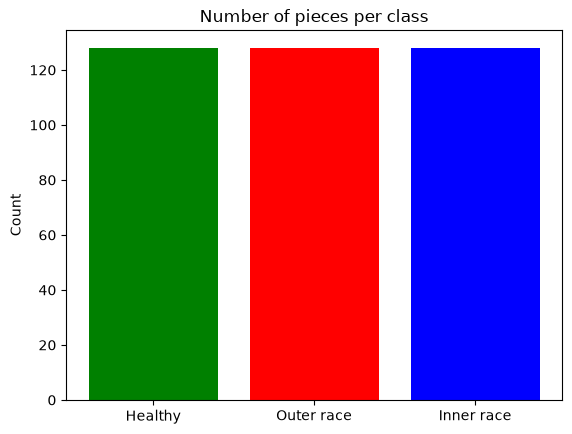

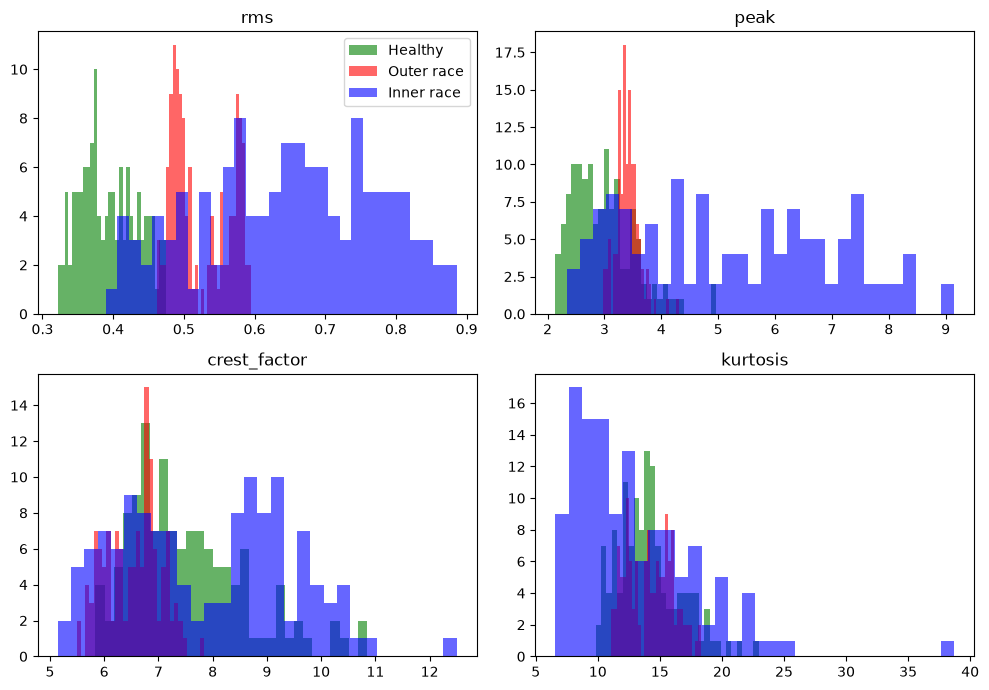

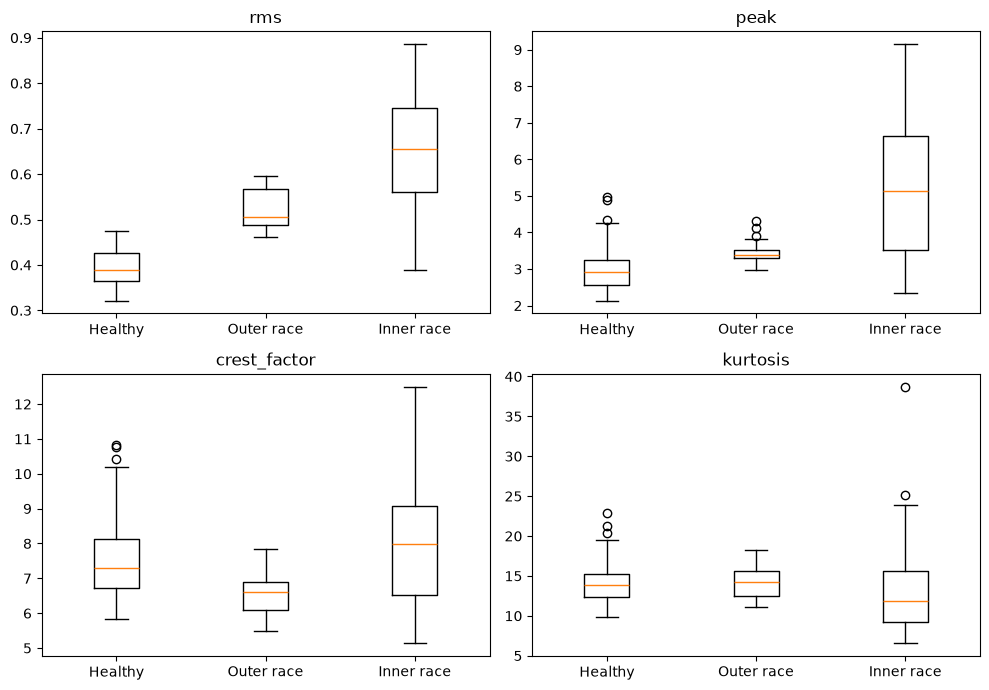

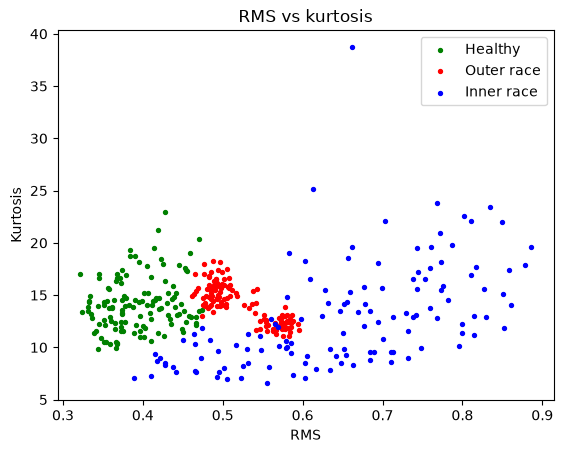


Train size: 306  Test size: 78
Train means after scaling (should be ~0): [ 0. -0. -0.  0.]
Train std after scaling (should be ~1): [1. 1. 1. 1.]
Test rows that also appear in the training set: 0

Baseline accuracy to beat: 0.333
no scaling     train F1 0.918 | test accuracy 0.897 | test macro F1 0.896
StandardScaler train F1 0.984 | test accuracy 1.000 | test macro F1 1.000


In [20]:
# Task I.2 : explore, clean and prepare bearing vibration data
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.io
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score

DATA_DIR = r"C:\Users\shishir\OneDrive\Desktop\MOD550 A3\Data set"
os.makedirs("figures", exist_ok=True)

# The 3 files: healthy bearing (0), outer-race damage (1), inner-race damage (2)
FILES = {'K001': ('N15_M01_F10_K001_1.mat', 0),
         'KA01': ('N15_M01_F10_KA01_1.mat', 1),
         'KI01': ('N15_M01_F10_KI01_1.mat', 2)}
NAMES = {0: 'Healthy', 1: 'Outer race', 2: 'Inner race'}

# ---------------------------------------------------------------- STEP 1: load
def load_signal(path):
    """Open a .mat file and return the vibration_1 signal as a list of numbers."""
    m = scipy.io.loadmat(path, squeeze_me=True, struct_as_record=False)
    key = [k for k in m if not k.startswith('__')][0]
    channel_names = [y.Name for y in m[key].Y]
    return np.asarray(m[key].Y[channel_names.index('vibration_1')].Data, float).ravel()

rows = []
for code, (filename, label) in FILES.items():
    if os.environ.get("DEMO"):                       # fake data, only for testing
        signal = np.random.default_rng(label).normal(0, 0.15 + 0.05 * label, 250000)
    else:
        path = glob.glob(os.path.join(DATA_DIR, '**', filename), recursive=True)[0]
        signal = load_signal(path)

    # Cut the long signal into pieces of 2000 samples; each piece = one row
    for i in range(len(signal) // 2000):
        piece = signal[i * 2000:(i + 1) * 2000]
        rms = np.sqrt(np.mean(piece ** 2))           # average vibration strength
        peak = np.max(np.abs(piece))                 # biggest spike
        mean, std = piece.mean(), piece.std()
        kurtosis = np.mean(((piece - mean) / std) ** 4)   # how "spiky" (normal = 3)
        rows.append({'piece': i, 'label': label, 'rms': rms, 'peak': peak,
                     'crest_factor': peak / rms, 'kurtosis': kurtosis})

df = pd.DataFrame(rows)
features = ['rms', 'peak', 'crest_factor', 'kurtosis']

# ------------------------------------------------- STEP 2: basic inspection
print("Shape (rows, columns):", df.shape)
print("\nData types:\n", df.dtypes)
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nClass counts:\n", df['label'].map(NAMES).value_counts())
print("\nSummary statistics:\n", df[features].describe().round(3))

# Lecture point: "accuracy lies" - compare with the baseline of always guessing
# the biggest class. A model must beat this to be useful.
baseline = df['label'].value_counts(normalize=True).max()
print("\nBaseline accuracy (always guess the biggest class):", round(baseline, 3))

# Lecture point: scale matters. Ratio of largest to smallest feature spread.
stds = df[features].std()
print("Feature std:\n", stds.round(4))
print("Largest : smallest std =", round(stds.max() / stds.min(), 1), ": 1")

# ------------------------------------ STEP 3: impossible values (physics rules)
# These can never happen with real data, so they must be errors.
impossible = (df['rms'] <= 0) | (df['crest_factor'] < 1) | (df['kurtosis'] < 1)
print("\nImpossible rows found:", impossible.sum())
df = df[~impossible]                                  # keep only the possible rows

# duplicates leak. If one copy lands in train and another in test,
# the model is tested on rows it has already seen. Drop them BEFORE splitting.
# (We ignore the 'piece' number so identical measurements count as duplicates.)
n_before = len(df)
df = df.drop_duplicates(subset=features + ['label'])
print("Duplicate rows removed before the split:", n_before - len(df))

# ------------------------------- STEP 4: outliers (unusual but possible values)
# IQR rule: a value is an outlier if it is far outside the middle 50% of the data.
for f in features:
    q1, q3 = df[f].quantile(0.25), df[f].quantile(0.75)
    iqr = q3 - q1
    n_out = ((df[f] < q1 - 1.5 * iqr) | (df[f] > q3 + 1.5 * iqr)).sum()
    print(f"Outliers in {f}: {n_out}")
# We KEEP outliers: sudden spikes are exactly what a damaged bearing produces.

# --------------------------------------------- STEP 5: class relationships
print("\nAverage of each feature per class:\n",
      df.groupby('label')[features].mean().round(3))
print("\nCorrelation between features:\n", df[features].corr().round(2))

# ------------------------------------------------------ STEP 6: figures
colors = {0: 'green', 1: 'red', 2: 'blue'}

# Figure 1: is the data balanced?
counts = df['label'].value_counts().sort_index()
plt.bar([NAMES[k] for k in counts.index], counts.values,
        color=[colors[k] for k in counts.index])
plt.title('Number of pieces per class'); plt.ylabel('Count')
plt.savefig('figures/fig1_class_balance.png'); plt.show()

# Figure 2: histograms - how are values spread, per class?
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, f in zip(axes.ravel(), features):
    for label in [0, 1, 2]:
        ax.hist(df[df.label == label][f], bins=30, alpha=0.6,
                color=colors[label], label=NAMES[label])
    ax.set_title(f)
axes[0, 0].legend()
plt.tight_layout(); plt.savefig('figures/fig2_histograms.png'); plt.show()

# Figure 3: boxplots - spread and outliers per class
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, f in zip(axes.ravel(), features):
    ax.boxplot([df[df.label == k][f] for k in [0, 1, 2]],
               tick_labels=[NAMES[k] for k in [0, 1, 2]])
    ax.set_title(f)
plt.tight_layout(); plt.savefig('figures/fig3_boxplots.png'); plt.show()

# Figure 4: can two features separate the classes?
for label in [0, 1, 2]:
    d = df[df.label == label]
    plt.scatter(d['rms'], d['kurtosis'], s=8, color=colors[label], label=NAMES[label])
plt.xlabel('RMS'); plt.ylabel('Kurtosis'); plt.legend(); plt.title('RMS vs kurtosis')
plt.savefig('figures/fig4_scatter.png'); plt.show()

# ----------------------------------------------------- STEP 7: preprocessing
# (a) Split into train (first 80% of each class) and test (last 20%).
#     We cut in time order instead of randomly, because neighbouring pieces of
#     the same recording look very alike - a random split would let the test
#     data "leak" into training.
train_parts, test_parts = [], []
for label in [0, 1, 2]:
    d = df[df.label == label].sort_values('piece')
    cut = int(len(d) * 0.8)
    train_parts.append(d.iloc[:cut]); test_parts.append(d.iloc[cut:])
train, test = pd.concat(train_parts), pd.concat(test_parts)
print("\nTrain size:", len(train), " Test size:", len(test))

# (b) Imputation: fill missing values with the median (we found none, but this
#     makes the pipeline safe). Learn the median from TRAIN data only.
imputer = SimpleImputer(strategy='median').fit(train[features])
X_train = imputer.transform(train[features])
X_test = imputer.transform(test[features])

# (c) Scaling: rms is around 0.2 but kurtosis can be 10, so many models would
#     treat kurtosis as "more important". StandardScaler gives every feature
#     mean 0 and standard deviation 1. Again, learn it from TRAIN data only.
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)
y_train, y_test = train['label'].values, test['label'].values

print("Train means after scaling (should be ~0):", X_train.mean(axis=0).round(2))
print("Train std after scaling (should be ~1):", X_train.std(axis=0).round(2))

# Leakage check : how many test rows also appear in train?
leak = test[features].round(8).merge(train[features].round(8), how='inner').shape[0]
print("Test rows that also appear in the training set:", leak)

# (d) Feature engineering: crest_factor (peak / rms) was created from existing
#     columns because it highlights spikes relative to normal vibration.

# ------------------------------------- STEP 8: quick check with an SVM
# Why scaling matters, shown with numbers (same idea as the lecture's wine example).
# We report macro F1 (every class counts equally) next to accuracy.
raw_train, raw_test = train[features].values, test[features].values

def evaluate(name, Xa, Xb):
    model = SVC(kernel='rbf', C=1.0, gamma='scale').fit(Xa, y_train)
    print(f"{name:14s} train F1 {f1_score(y_train, model.predict(Xa), average='macro'):.3f} | "
          f"test accuracy {accuracy_score(y_test, model.predict(Xb)):.3f} | "
          f"test macro F1 {f1_score(y_test, model.predict(Xb), average='macro'):.3f}")

print("\nBaseline accuracy to beat:", round(baseline, 3))
evaluate("no scaling", raw_train, raw_test)
evaluate("StandardScaler", X_train, X_test)


Markdown
#Task I.2: Data Exploration and Preparation: Observations

1. Data inspection and quality checks. The feature matrix has 384 rows and 6 columns. Each row is one 2000-sample vibration segment, with four computed features (RMS, peak, crest factor, kurtosis), a segment index and a class label. All features are numeric (float64). There are no missing values and no duplicate rows. The classes are balanced, with 128 segments each for healthy, outer-race and inner-race (fig1_class_balance.png). The majority-class baseline accuracy is therefore 0.333, and no resampling is needed. The balance comes from the sampling design, not from real-world frequencies, where healthy bearings would dominate.

2. Anomalies and impossible values. Three physical rules were tested: RMS ≤ 0, crest factor < 1 and kurtosis < 1 (impossible by definition). No rows violated them, so none were removed. Using the 1.5×IQR rule, 10 RMS, 57 peak, 5 crest-factor and 9 kurtosis values were flagged as statistical outliers. The peak count is inflated because the rule was applied to all classes pooled, so the high peaks of the inner-race class are flagged as outliers when they are really a class difference. The outliers were kept, because impulsive segments are physically meaningful in bearing faults and removing them would delete the signal of interest.

3. Distributions and class relationships. Feature spreads differ by about 26:1 (peak and kurtosis against RMS), which motivates scaling. Class means show RMS rising from healthy (0.39) to outer race (0.52) to inner race (0.65), and peak is highest for the inner race (5.2, against 3.0 and 3.4). Kurtosis barely differs between classes (14.1, 14.2 and 12.9). RMS and peak are strongly correlated (0.87), so they carry overlapping information.

4. Visualizations and diagnostic findings.

Histograms (fig2_histograms.png): RMS and peak show the clearest class differences. Healthy segments sit at low values (RMS about 0.32 to 0.47). Outer-race segments are concentrated within a relatively narrow RMS range around 0.47-0.60, indicating more consistent vibration levels than the inner-race class. Inner-race segments spread over a much wider range (RMS about 0.39 to 0.89, peak up to about 9) with a long right tail. Crest factor and kurtosis overlap heavily across classes.
Boxplots (fig3_boxplots.png): Median RMS increases from healthy to outer to inner race, and the inner race has the largest spread in every feature. Kurtosis medians are similar across classes, so kurtosis does not discriminate them on its own.
RMS vs kurtosis scatter (fig4_scatter.png): Healthy and outer-race segments form fairly compact groups that RMS separates reasonably well. Inner-race points are widely scattered and overlap both groups, so the classes are not linearly separable in these two features. This motivates a non-linear (RBF) SVM.
Overall, RMS and peak provide the strongest visual separation between bearing conditions. Healthy bearings exhibit the lowest vibration levels, outer-race faults show intermediate values, and inner-race faults display both the highest vibration levels and the greatest variability. Crest factor and kurtosis contribute additional information but show considerably greater overlap between classes. The wide inner-race spread and the two outer-race clusters suggest the vibration level changes within a recording, which is a further reason to avoid a random split.

5. Preprocessing.

Split: The data was split 80/20 per class in time order (306 train, 78 test, 102 and 26 per class). Neighbouring segments of one recording are strongly similar, so a random split would leak information. A check found 0 test rows that also appear in the training set.
Imputation: A median imputer was included as a safeguard, although no values were missing.
Feature engineering: Crest factor (peak/RMS) was derived from existing columns because it highlights spikes relative to the normal vibration level.
Scaling: StandardScaler was fitted on the training data only and applied to the test data, which keeps test information out of training. With an RBF SVM, test macro F1 rose from 0.896 without scaling to 1.000 with scaling (test accuracy 0.897 to 1.000), well above the 0.333 baseline.

6. Limitation. Each class comes from a single recording, and the test set is the final 20% of each recording. The perfect test score is therefore probably optimistic and does not show generalisation to other bearings. Testing on additional recordings would be the proper next step.

In [21]:
#Task I.3: Classification Strategy and Baseline
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.dummy import DummyClassifier
from sklearn.svm import SVC
def evaluate_svm_baseline(X, y, cv_strategy, feature_cols):
    """
    Evaluates an SVM pipeline and a dummy classifier baseline using cross-validation.

    Parameters:
    - X (pd.DataFrame): Dataset features.
    - y (pd.Series): Target labels.
    - cv_strategy (StratifiedKFold): Cross-validation strategy.
    - feature_cols (list): Features to use.

    Returns:
    - tuple: (svm_scores, dummy_scores) macro F1 scores.
    """
cv = StratifiedKFold(n_splits=5, shuffle=False)       # no shuffling: keeps blocks together
pipe = make_pipeline(StandardScaler(), SVC(kernel='rbf'))
print("SVM CV macro F1:", cross_val_score(pipe, train[features], y_train, cv=cv, scoring='f1_macro').round(3))

dummy = DummyClassifier(strategy='most_frequent')
print("Baseline CV macro F1:", cross_val_score(dummy, train[features], y_train, cv=cv, scoring='f1_macro').round(3))

SVM CV macro F1: [0.984 1.    0.984 1.    0.967]
Baseline CV macro F1: [0.163 0.165 0.165 0.165 0.165]


Markdown
#Task I.3: Classification Strategy and Baseline
1. Training

Each class (128 segments) is split in time order: the first 80% for training and the last 20% for testing, giving 306 training and 78 test segments. The training data is divided into 5 unshuffled folds for validation and tuning. The test set is used once, for the final evaluation. Time order is used because neighboring segments of a recording are similar, so a random split could place near-copies in both sets.

2. Leakage

Risks: near-copy neighboring segments across splits; scaling fitted on all data; duplicate rows; tuning on test data. Mitigations: time-ordered split, unshuffled folds, scaler fitted inside each fold via a pipeline, duplicates removed before the split (0 test rows appear in training), test set untouched until the end. Residual risk: each class comes from one recording, so test data shares a recording with training and scores may be optimistic until whole recordings are held out.
 
 3. Primary Selection Metric

The primary metric is macro F1, measured on the validation folds. It scores each of the three health states separately and averages them, so every class counts equally. Always guessing the biggest class scores about 0.165, while the SVM averages 0.987.

MarkDown
Task I.4: SVM Modeling

In [ ]:
#Task I.4: SVM Modeling

Explanation of kernel/hyperparameter choices

MarkDown
Task I.5 -- Model Evaluation 


In [ ]:
#Task I.5 -- Model Evaluation

MarkDown
Evaluation and comparison against the baseline

#Individual Analysis -- Shishir Dahal 